In [4]:
import pandas as pd
import numpy as np

In [5]:
df=pd.read_csv('/Users/nidagallusandeep/Downloads/customer_churn_20000(1).csv')

In [6]:
df.head()

,CustomerID,Gender,SeniorCitizen,Partner,Dependents,Tenure,PhoneService,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,100001,Female,0,Yes,No,34,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,One year,No,Electronic check,35.25,1236.53,No
1,100002,Male,0,Yes,No,16,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Electronic check,35.10,485.27,No
2,100003,Male,0,No,No,66,Yes,Fiber optic,No,No,Yes,No,No,Month-to-month,Yes,Credit card,109.34,7189.81,No
3,100004,Female,0,Yes,Yes,16,Yes,DSL,Yes,No,Yes,No,No,Month-to-month,No,Mailed check,55.30,843.96,No
4,100005,Female,0,Yes,No,8,Yes,Fiber optic,Yes,No,No,No,No,Two year,No,Bank transfer,18.00,137.80,No


In [7]:
df.shape

(20000, 19)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        20000 non-null  int64  
 1   Gender            20000 non-null  object 
 2   SeniorCitizen     20000 non-null  int64  
 3   Partner           20000 non-null  object 
 4   Dependents        20000 non-null  object 
 5   Tenure            20000 non-null  int64  
 6   PhoneService      20000 non-null  object 
 7   InternetService   20000 non-null  object 
 8   OnlineSecurity    20000 non-null  object 
 9   OnlineBackup      20000 non-null  object 
 10  DeviceProtection  20000 non-null  object 
 11  TechSupport       20000 non-null  object 
 12  StreamingTV       20000 non-null  object 
 13  Contract          20000 non-null  object 
 14  PaperlessBilling  20000 non-null  object 
 15  PaymentMethod     20000 non-null  object 
 16  MonthlyCharges    20000 non-null  float6

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.isnull().sum()

CustomerID          0
Gender              0
SeniorCitizen       0
Partner             0
Dependents          0
Tenure              0
PhoneService        0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [29]:
df["Gender"].value_counts()

Gender
Female    10072
Male       9928
Name: count, dtype: int64

In [30]:
df["Partner"].value_counts()

Partner
No     10512
Yes     9488
Name: count, dtype: int64

In [31]:
df["Dependents"].value_counts()

Dependents
No     14018
Yes     5982
Name: count, dtype: int64

In [32]:
df["Churn"].value_counts()

Churn
No     17802
Yes     2198
Name: count, dtype: int64

In [28]:
df.head()

,Gender,SeniorCitizen,Partner,Dependents,Tenure,PhoneService,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,34,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,One year,No,Electronic check,35.25,1236.53,No
1,Male,0,Yes,No,16,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Electronic check,35.10,485.27,No
2,Male,0,No,No,66,Yes,Fiber optic,No,No,Yes,No,No,Month-to-month,Yes,Credit card,109.34,7189.81,No
3,Female,0,Yes,Yes,16,Yes,DSL,Yes,No,Yes,No,No,Month-to-month,No,Mailed check,55.30,843.96,No
4,Female,0,Yes,No,8,Yes,Fiber optic,Yes,No,No,No,No,Two year,No,Bank transfer,18.00,137.80,No


In [11]:
df.describe()

,CustomerID,SeniorCitizen,Tenure,MonthlyCharges,TotalCharges
count,20000.000000,20000.00000,20000.000000,20000.000000,20000.000000
mean,110000.500000,0.15980,36.077700,71.224611,2568.236499
std,5773.647028,0.36643,20.949926,27.911479,1895.320662
min,100001.000000,0.00000,0.000000,18.000000,0.000000
25%,105000.750000,0.00000,18.000000,51.815000,1008.410000
50%,110000.500000,0.00000,36.000000,72.255000,2202.860000
75%,115000.250000,0.00000,54.000000,91.250000,3804.742500
max,120000.000000,1.00000,72.000000,130.000000,9493.200000


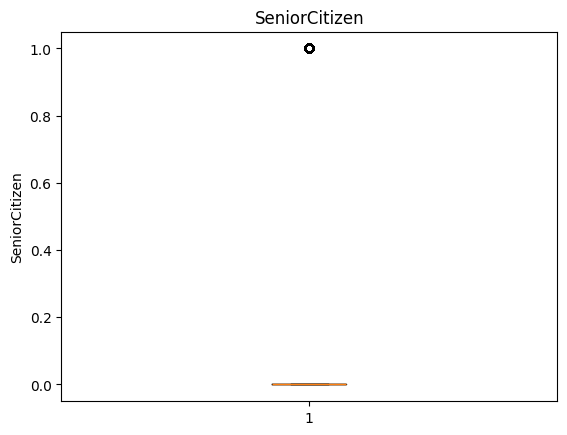

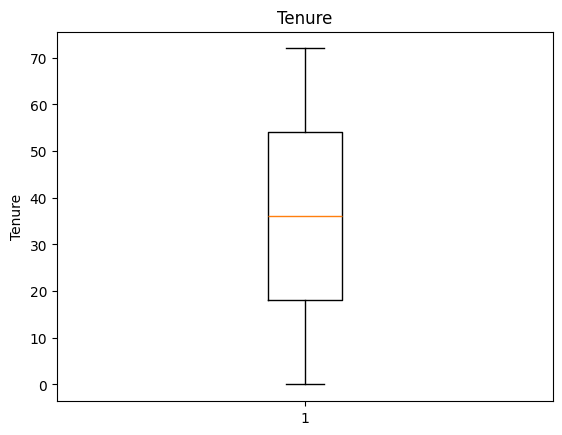

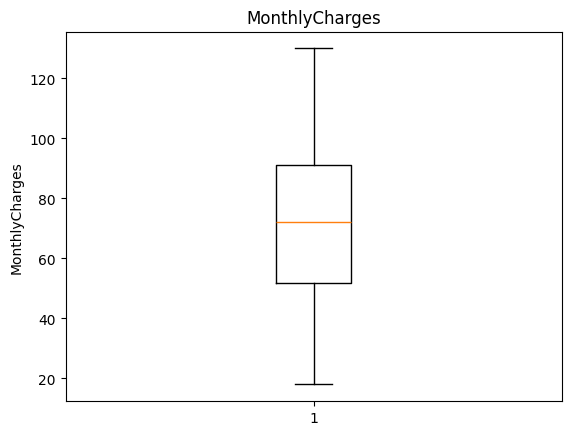

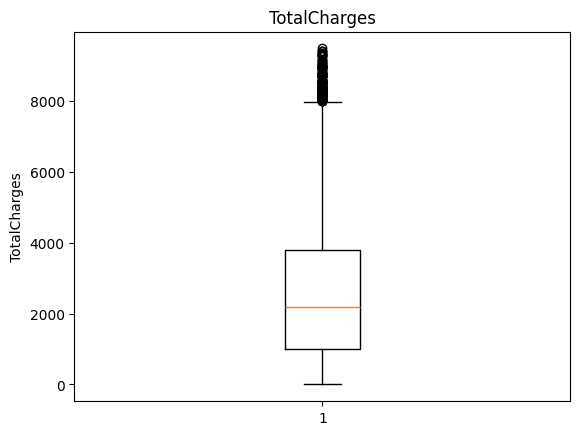

In [33]:
num_cols = df.select_dtypes(include=["int64", "float64"]).columns
for col in num_cols:
    plt.boxplot(df[col])
    plt.title(col)
    plt.ylabel(col)
    plt.show()

In [12]:
df=df.drop(columns="CustomerID")

In [13]:
X=df.drop(columns="Churn",axis=1)
y=df["Churn"]

In [14]:
num_cal=X.select_dtypes(include=np.number).columns.tolist()
cat_cal=X.select_dtypes(include="object").columns.tolist()

In [15]:
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [16]:
numerical_transformer=Pipeline(steps=[
    ("impute",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

categorical_transformer=Pipeline(steps=[
    ("impute",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])

In [17]:
preprocessing=ColumnTransformer(transformers=[
    ("num",numerical_transformer,num_cal),
    ("cat",categorical_transformer,cat_cal)
])

In [18]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(16000, 17)
(4000, 17)
(16000,)
(4000,)


In [19]:
from sklearn.ensemble import GradientBoostingClassifier
model=Pipeline(steps=[
    ("preprocessing",preprocessing),
    ("classifier",GradientBoostingClassifier(random_state=42))
])
model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['Gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying `

In [20]:
y_pred=model.predict(X_test)

In [21]:
from sklearn.metrics import accuracy_score
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)

Accuracy: 0.89575


In [22]:
from sklearn.metrics import precision_score
precision = precision_score(y_test, y_pred, pos_label="Yes")
print("Precision:", precision)

Precision: 0.5294117647058824


In [23]:
from sklearn.metrics import recall_score
recall = recall_score(y_test, y_pred, pos_label="Yes")
print("Recall:", recall)

Recall: 0.04295942720763723


In [24]:
from sklearn.metrics import f1_score
f1 = f1_score(y_test, y_pred, pos_label="Yes")
print("F1 Score:", f1)

F1 Score: 0.07947019867549669


In [25]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

          No       0.90      1.00      0.94      3581
         Yes       0.53      0.04      0.08       419

    accuracy                           0.90      4000
   macro avg       0.71      0.52      0.51      4000
weighted avg       0.86      0.90      0.85      4000



# Confusion Matrix

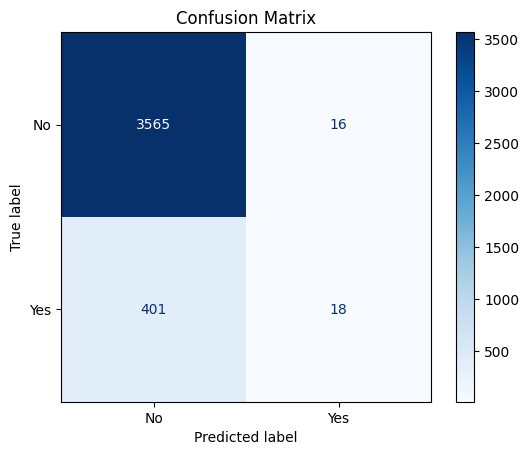

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# ROC-AUC Curve

ROC-AUC Score: 0.761962665593203


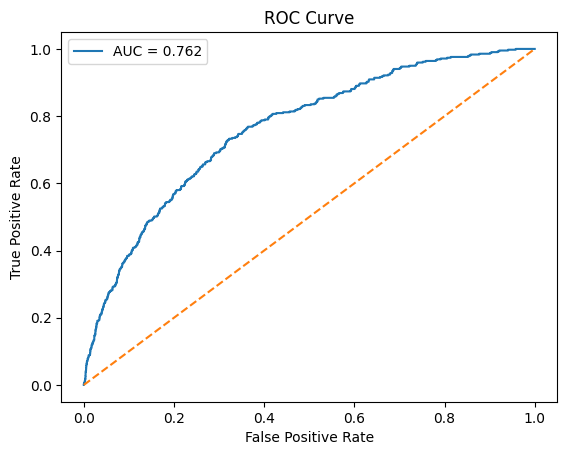

In [34]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt
y_prob = model.predict_proba(X_test)[:, 1]
auc = roc_auc_score((y_test == "Yes").astype(int), y_prob)
print("ROC-AUC Score:", auc)

fpr, tpr, thresholds = roc_curve(
    (y_test == "Yes").astype(int),
    y_prob)

plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()